In [2]:
# =============================================================
# [Cell 1] 데이터 로드 및 구조 확인 (AI 학습용 EDA - Step 1)
# 목적: mct_clean.csv가 올바르게 로드됐는지 확인하고,
#       본격 분석 전에 데이터 구조 / 상태 / 이벤트 개수를 점검한다.
# =============================================================

# 1. 라이브러리 import
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)   # 열 잘림 방지
pd.set_option("display.width", 200)

# 2. mct_clean.csv 불러오기
#    - 파싱 단계에서 utf-8-sig(BOM 포함)로 저장됐으므로 동일 인코딩 사용
#    - low_memory=False: 혼합 dtype 경고 방지
CLEAN_PATH = "../output/mct_clean.csv"   # notebooks/ 기준 상대경로 (필요시 절대경로로 수정)

df = pd.read_csv(CLEAN_PATH, encoding="utf-8-sig", low_memory=False)

# timestamp를 datetime으로 변환 (원본 형식: 2026-05-01 00:00:04,522)
df["timestamp"] = pd.to_datetime(
    df["timestamp"], format="%Y-%m-%d %H:%M:%S,%f", errors="coerce"
)

# 3. shape 확인
print("shape (행, 열):", df.shape)

# 4. 컬럼 목록 확인
print("\n컬럼 개수:", len(df.columns))
print("컬럼 목록:")
print(list(df.columns))

# 5. timestamp 자료형 및 범위 확인
print("\ntimestamp dtype:", df["timestamp"].dtype)
print("timestamp 결측:", df["timestamp"].isna().sum())
print("기간:", df["timestamp"].min(), "~", df["timestamp"].max())

# 6. STATUS별 데이터 개수
print("\n[STATUS별 개수]")
print(df["status"].value_counts(dropna=False))

# 7. 주요 이벤트 플래그 개수 (build_clean_dataset.py에서 생성된 bool 플래그)
flag_cols = ["is_alarm", "is_emergency", "is_reset",
             "is_spindle_overload", "is_abnormal_interval", "has_event"]

print("\n[주요 이벤트 개수]")
print(df[flag_cols].sum())

# 참고: 원본 코드값 분포도 함께 확인 (플래그 정의와 대조용)
print("\n[원본 코드값 확인]")
print("alarm 값 분포:    ", df["alarm"].value_counts().to_dict())
print("emergency 값 분포:", df["emergency"].value_counts().to_dict())

shape (행, 열): (481648, 31)

컬럼 개수: 31
컬럼 목록:
['timestamp', 'machine', 'feed_rate', 'spindle_rate', 'x_axis', 'y_axis', 'z_axis', 'current_tool', 'x_load', 'y_load', 'z_load', 'spindle_load', 'spindle_rpm', 'delta_spindle_rpm', 'status', 'aut_mode', 'run_mode', 'emergency', 'alarm', 'error_message', 'source_file', 'interval_seconds', 'x_axis_mm', 'y_axis_mm', 'z_axis_mm', 'is_alarm', 'is_emergency', 'is_reset', 'is_spindle_overload', 'is_abnormal_interval', 'has_event']

timestamp dtype: datetime64[ns]
timestamp 결측: 0
기간: 2026-05-01 00:00:04.522000 ~ 2026-05-31 23:59:57.595000

[STATUS별 개수]
status
STATUS_RUN      243319
STATUS_READY    238313
STATUS_ERROR        16
Name: count, dtype: int64

[주요 이벤트 개수]
is_alarm                16
is_emergency             0
is_reset                 4
is_spindle_overload     60
is_abnormal_interval    17
has_event               97
dtype: int64

[원본 코드값 확인]
alarm 값 분포:     {0: 481632, 1: 16}
emergency 값 분포: {0: 481644, 2: 4}


In [3]:
# =============================================================
# [Cell 2] STATUS_RUN 내부 상태 진단 (필터링 없음)
# 목적: RUN 243,319행 안에서 RPM/FEED/LOAD의 0 vs >0 조합이
#       각각 얼마나 존재하는지, 조합별로 공구·모드·부하가
#       어떻게 나타나는지 확인한다.
#       => "실제 절삭 중" 정의 조건을 판단하기 위한 근거 수집.
# 아직 어떤 조건으로도 데이터를 걸러내지 않는다.
# =============================================================

# RUN 구간만 분리 (ERROR/READY 제외). 여기서는 필터가 아니라 상태 분리임.
run = df[df["status"] == "STATUS_RUN"].copy()
print("STATUS_RUN 행 수:", len(run))

# --- 1) 각 변수의 0 vs >0 단순 분포 ---
print("\n[개별 변수: =0 vs >0]")
for col in ["spindle_rpm", "feed_rate", "spindle_load"]:
    zero = (run[col] == 0).sum()
    pos  = (run[col] >  0).sum()
    neg  = (run[col] <  0).sum()   # 음수 존재 여부도 점검
    print(f"  {col:14s} | =0: {zero:>7,} ({zero/len(run)*100:5.1f}%)"
          f" | >0: {pos:>7,} ({pos/len(run)*100:5.1f}%)"
          f" | <0: {neg:,}")

# --- 2) RPM x FEED 4개 조합 개수/비율 ---
run["rpm_pos"]  = run["spindle_rpm"] > 0
run["feed_pos"] = run["feed_rate"]  > 0
run["load_pos"] = run["spindle_load"] > 0

print("\n[RPM x FEED 조합]")
combo = (run.groupby(["rpm_pos", "feed_pos"])
             .size().rename("count").reset_index())
combo["pct"] = (combo["count"] / len(run) * 100).round(2)
# 읽기 쉽게 라벨 붙이기
def lbl(r, f):
    return f"RPM{'>0' if r else '=0'} & FEED{'>0' if f else '=0'}"
combo["label"] = combo.apply(lambda x: lbl(x["rpm_pos"], x["feed_pos"]), axis=1)
print(combo[["label", "count", "pct"]].to_string(index=False))

# --- 3) RPM x FEED x LOAD 8개 조합 (부하까지 포함) ---
print("\n[RPM x FEED x LOAD 조합]")
combo3 = (run.groupby(["rpm_pos", "feed_pos", "load_pos"])
              .size().rename("count").reset_index())
combo3["pct"] = (combo3["count"] / len(run) * 100).round(2)
combo3 = combo3.sort_values("count", ascending=False)
print(combo3.to_string(index=False))

# --- 4) RPM x FEED 조합별로 공구·모드·부하 특성 ---
# 조합 라벨을 한 컬럼으로 만들어 groupby
run["combo"] = run.apply(lambda x: lbl(x["rpm_pos"], x["feed_pos"]), axis=1)

print("\n[조합별 SPINDLE_LOAD 요약]")
print(run.groupby("combo")["spindle_load"]
         .agg(["count", "mean", "median", "max"]).round(2).to_string())

print("\n[조합별 RUN_MODE 분포]")
print(pd.crosstab(run["combo"], run["run_mode"]))

print("\n[조합별 AUT_MODE 분포]")
print(pd.crosstab(run["combo"], run["aut_mode"]))

print("\n[조합별 CURRENT_TOOL 상위 5개]")
for c, sub in run.groupby("combo"):
    top = sub["current_tool"].value_counts().head(5).to_dict()
    print(f"  {c:22s} -> {top}")

STATUS_RUN 행 수: 243319

[개별 변수: =0 vs >0]
  spindle_rpm    | =0:  23,263 (  9.6%) | >0: 220,056 ( 90.4%) | <0: 0
  feed_rate      | =0:  17,615 (  7.2%) | >0: 225,704 ( 92.8%) | <0: 0
  spindle_load   | =0:  23,171 (  9.5%) | >0: 220,148 ( 90.5%) | <0: 0

[RPM x FEED 조합]
         label  count   pct
RPM=0 & FEED=0  16754  6.89
RPM=0 & FEED>0   6509  2.68
RPM>0 & FEED=0    861  0.35
RPM>0 & FEED>0 219195 90.09

[RPM x FEED x LOAD 조합]
 rpm_pos  feed_pos  load_pos  count   pct
    True      True      True 219194 90.09
   False     False     False  16635  6.84
   False      True     False   6497  2.67
    True     False      True    823  0.34
   False     False      True    119  0.05
    True     False     False     38  0.02
   False      True      True     12  0.00
    True      True     False      1  0.00

[조합별 SPINDLE_LOAD 요약]
                 count   mean  median  max
combo                                     
RPM=0 & FEED=0   16754   0.01     0.0    8
RPM=0 & FEED>0    6509   0.00     

In [4]:
# =============================================================
# [Cell 3] 공구별 절삭 정상 분포 분석 (잠정 모집단: RPM>0 & FEED>0)
# 목적: 실제 절삭 구간(219,195행)을 공구별로 나눠
#       SPINDLE_LOAD / SPINDLE_RPM / FEED_RATE의 정상 분포를 파악한다.
#       => 공구마다 정상 범위가 다른지 확인하고,
#          이후 가상 이상 생성에 쓸 "정상 기준값" 재료를 만든다.
# 주의: RPM>0 & FEED=0 (861행)은 여기서 제외(보존)하며 손대지 않는다.
# =============================================================

# --- 절삭 잠정 모집단 정의 (여기서만 사용하는 분석용 뷰) ---
cut = df[(df["status"] == "STATUS_RUN")
         & (df["spindle_rpm"] > 0)
         & (df["feed_rate"]  > 0)].copy()

print("절삭 잠정 모집단 (RPM>0 & FEED>0):", len(cut), "행")
print("전체 공구 종류 수:", cut["current_tool"].nunique())
print("공구 목록:", sorted(cut["current_tool"].unique()))

# --- 공구별 분포 요약 함수 ---
def tool_profile(data, col):
    g = data.groupby("current_tool")[col]
    prof = pd.DataFrame({
        "n":      g.size(),
        "mean":   g.mean().round(2),
        "median": g.median().round(2),
        "std":    g.std().round(2),
        "p5":     g.quantile(0.05).round(2),
        "p95":    g.quantile(0.95).round(2),
        "p99":    g.quantile(0.99).round(2),
        "min":    g.min(),
        "max":    g.max(),
    })
    # 공구를 데이터 개수 많은 순으로 정렬 (주력 공구가 위로)
    return prof.sort_values("n", ascending=False)

pd.set_option("display.max_rows", None)

for col in ["spindle_load", "spindle_rpm", "feed_rate"]:
    print("\n" + "=" * 78)
    print(f"[공구별 {col.upper()} 정상 분포]  (RPM>0 & FEED>0 기준)")
    print("=" * 78)
    print(tool_profile(cut, col).to_string())

# --- 공구 간 편차가 실제로 큰지 한눈에 보기 (중앙값 비교) ---
print("\n" + "=" * 78)
print("[공구별 중앙값 비교 요약]  공구에 따라 정상 범위가 갈리는지 확인")
print("=" * 78)
summary = cut.groupby("current_tool").agg(
    n=("spindle_load", "size"),
    load_median=("spindle_load", "median"),
    load_p95=("spindle_load", lambda s: round(s.quantile(0.95), 1)),
    rpm_median=("spindle_rpm", "median"),
    feed_median=("feed_rate", "median"),
).sort_values("n", ascending=False)
print(summary.to_string())

# 참고: 데이터가 매우 적은 공구는 분포 추정이 불안정하므로 표시만 해둠
few = summary[summary["n"] < 500]
if len(few):
    print("\n[주의] 표본 500행 미만 공구 (정상범위 추정 불안정, 참고용):",
          list(few.index))
    

절삭 잠정 모집단 (RPM>0 & FEED>0): 219195 행
전체 공구 종류 수: 19
공구 목록: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(18), np.int64(19), np.int64(20)]

[공구별 SPINDLE_LOAD 정상 분포]  (RPM>0 & FEED>0 기준)
                  n   mean  median   std    p5    p95    p99  min  max
current_tool                                                          
4             66169  10.60    11.0  0.86  10.0  11.00  11.00    0   82
1             33209   8.17     8.0  2.49   6.0  12.00  14.00    5   82
3             23994  10.73    11.0  1.48  10.0  11.00  12.00    9   84
6             19741  12.03    12.0  1.03  11.0  13.00  13.00   10   78
13            17002  14.37    14.0  0.58  14.0  15.00  15.00   14   55
10            15395  13.23    13.0  0.83  13.0  14.00  14.00   13   83
8              8109  12.48    12.0  0.90  12.0  13.00  13.00   11   

In [5]:
# =============================================================
# [Cell 4] RPM_ERROR (지령-실제) 공구별 정상 분포 분석
# 모집단: 절삭 잠정 정상 (RPM>0 & FEED>0, 219,195행)
# 정의: RPM_ERROR = SPINDLE_RATE - SPINDLE_RPM  (원본 두 컬럼 직접 사용)
# 목적: 정상 절삭 중 지령/실제 RPM 편차 범위를 파악해
#       'RPM 편차 증가' 가상 이상의 기준값 재료를 만든다.
# =============================================================

cut = df[(df["status"] == "STATUS_RUN")
         & (df["spindle_rpm"] > 0)
         & (df["feed_rate"]  > 0)].copy()

# --- RPM_ERROR 직접 계산 (지령 SPINDLE_RATE - 실제 SPINDLE_RPM) ---
cut["rpm_error"] = cut["spindle_rate"] - cut["spindle_rpm"]
# 부호와 무관한 편차 크기도 함께 봄 (이상은 방향과 상관없이 '벌어짐'이 핵심)
cut["rpm_abs_error"] = cut["rpm_error"].abs()

# --- 0) 전체 수준 요약 ---
print("절삭 모집단:", len(cut), "행")
print("\n[전체 RPM_ERROR 요약 (부호 있는 편차)]")
print(cut["rpm_error"].describe(
    percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2).to_string())
print("\n[전체 |RPM_ERROR| 요약 (편차 크기)]")
print(cut["rpm_abs_error"].describe(
    percentiles=[0.5, 0.95, 0.99]).round(2).to_string())

# 편차가 정확히 0인 비율 (정상 시 얼마나 지령=실제인가)
zero_ratio = (cut["rpm_error"] == 0).mean() * 100
print(f"\nRPM_ERROR == 0 비율: {zero_ratio:.1f}%")
print(f"|RPM_ERROR| <= 5 비율: {(cut['rpm_abs_error'] <= 5).mean()*100:.1f}%")

# --- 1) SPINDLE_RATE vs SPINDLE_RPM 상관관계 ---
corr_all = cut["spindle_rate"].corr(cut["spindle_rpm"])
print("\n" + "=" * 70)
print(f"[전체 상관관계] corr(SPINDLE_RATE, SPINDLE_RPM) = {corr_all:.6f}")
print("=" * 70)

# 공구별 상관도 (공구 내에서도 지령↔실제가 잘 맞는지)
print("\n[공구별 corr(SPINDLE_RATE, SPINDLE_RPM)]  n>=500 공구만")
corr_by_tool = (cut.groupby("current_tool")
                   .apply(lambda g: g["spindle_rate"].corr(g["spindle_rpm"])
                          if len(g) >= 2 else np.nan)
                   .round(4).rename("corr_rate_rpm"))
n_by_tool = cut.groupby("current_tool").size().rename("n")
corr_tbl = pd.concat([n_by_tool, corr_by_tool], axis=1)
print(corr_tbl[corr_tbl["n"] >= 500].to_string())

# --- 2) 공구별 RPM_ERROR 분포 (부호 있는 편차) ---
def err_profile(data, col):
    g = data.groupby("current_tool")[col]
    prof = pd.DataFrame({
        "n":      g.size(),
        "mean":   g.mean().round(2),
        "median": g.median().round(2),
        "std":    g.std().round(2),
        "p5":     g.quantile(0.05).round(2),
        "p95":    g.quantile(0.95).round(2),
        "p99":    g.quantile(0.99).round(2),
        "min":    g.min(),
        "max":    g.max(),
    })
    return prof.sort_values("n", ascending=False)

pd.set_option("display.max_rows", None)

print("\n" + "=" * 78)
print("[공구별 RPM_ERROR = SPINDLE_RATE - SPINDLE_RPM 분포]  (부호 있음)")
print("=" * 78)
print(err_profile(cut, "rpm_error").to_string())

print("\n" + "=" * 78)
print("[공구별 |RPM_ERROR| 분포]  (편차 크기 - 이상 기준 후보)")
print("=" * 78)
print(err_profile(cut, "rpm_abs_error").to_string())

# --- 3) 표본 부족 공구 표시 ---
few = n_by_tool[n_by_tool < 500]
if len(few):
    print("\n[주의] 표본 500행 미만 공구 (편차 추정 불안정):", list(few.index))

절삭 모집단: 219195 행

[전체 RPM_ERROR 요약 (부호 있는 편차)]
count    219195.00
mean          1.05
std          41.14
min         -31.00
1%           -5.00
5%           -4.00
50%           1.00
95%           4.00
99%           6.00
max        5339.00

[전체 |RPM_ERROR| 요약 (편차 크기)]
count    219195.00
mean          2.68
std          41.07
min           0.00
50%           1.00
95%           5.00
99%           6.00
max        5339.00

RPM_ERROR == 0 비율: 4.3%
|RPM_ERROR| <= 5 비율: 98.4%

[전체 상관관계] corr(SPINDLE_RATE, SPINDLE_RPM) = 0.999952

[공구별 corr(SPINDLE_RATE, SPINDLE_RPM)]  n>=500 공구만
                  n  corr_rate_rpm
current_tool                      
1             33209         0.0076
2              4108         0.9351
3             23994         0.0030
4             66169         0.0020
5              6655        -0.0274
6             19741        -0.0104
8              8109         0.0061
10            15395         0.9522
11             1481         0.0143
12             1952            NaN
13   

C:\Users\rbcks\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\rbcks\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\rbcks\AppData\Local\Temp\ipykernel_21104\193983311.py:41: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g["spindle_rate"].corr(g["spindle_rpm"])


In [6]:
# =============================================================
# [Cell 5] 윈도우 변동성 분석 (30초 / 1분 / 3분 / 5분 비교)
# 모집단: 절삭 잠정 정상 (RPM>0 & FEED>0)
# 목적: 정상 절삭 중 시간 윈도우별 변동성(Feature)이 어느 정도인지 확인,
#       XGBoost용 윈도우 크기 하나를 판단할 근거를 만든다.
# 주의: 가상 이상 생성/모델 학습 없음. 특수공구(19/2) 별도 분석 없음.
# =============================================================

# --- 절삭 모집단 준비 (시간순 정렬 + RPM_ERROR 계산) ---
cut = df[(df["status"] == "STATUS_RUN")
         & (df["spindle_rpm"] > 0)
         & (df["feed_rate"]  > 0)].copy()
cut = cut.sort_values("timestamp").reset_index(drop=True)
cut["rpm_error"]     = cut["spindle_rate"] - cut["spindle_rpm"]
cut["abs_rpm_error"] = cut["rpm_error"].abs()
cut["date"]          = cut["timestamp"].dt.date

WINDOWS = {"30s": "30s", "1min": "60s", "3min": "180s", "5min": "300s"}

# --- 시간 기반 롤링으로 윈도우 Feature 생성 ---
# 각 행 시점에서 '과거 W초' 구간을 하나의 윈도우로 봄.
# 하루(date) 단위로 그룹핑해 자정 경계를 넘지 않게 함.
def build_window_features(data, win):
    g = data.groupby("date", group_keys=False)

    def roll(s, how):
        # timestamp를 인덱스로 한 시간 롤링
        return (s.set_index("timestamp")
                 .rolling(win))

    feats = pd.DataFrame(index=data.index)
    # 윈도우 내 표본 수 (신뢰도 확인용)
    tmp = data.set_index("timestamp")
    grp = data.groupby("date")

    out = []
    for _, sub in grp:
        sub = sub.set_index("timestamp").sort_index()
        r = sub.rolling(win)
        f = pd.DataFrame(index=sub.index)
        f["win_n"] = r["spindle_rpm"].count()

        # SPINDLE_RPM
        f["rpm_mean"] = r["spindle_rpm"].mean()
        f["rpm_std"]  = r["spindle_rpm"].std()
        f["rpm_min"]  = r["spindle_rpm"].min()
        f["rpm_max"]  = r["spindle_rpm"].max()
        f["rpm_range"] = f["rpm_max"] - f["rpm_min"]

        # SPINDLE_LOAD
        f["load_mean"] = r["spindle_load"].mean()
        f["load_std"]  = r["spindle_load"].std()
        f["load_max"]  = r["spindle_load"].max()
        f["load_min"]  = r["spindle_load"].min()
        f["load_range"] = f["load_max"] - f["load_min"]

        # FEED_RATE
        f["feed_mean"] = r["feed_rate"].mean()
        f["feed_std"]  = r["feed_rate"].std()
        f["feed_min"]  = r["feed_rate"].min()
        f["feed_max"]  = r["feed_rate"].max()
        f["feed_range"] = f["feed_max"] - f["feed_min"]

        # RPM_ERROR
        f["rpmerr_mean"]   = r["rpm_error"].mean()
        f["rpmerr_std"]    = r["rpm_error"].std()
        f["rpmerr_absmax"] = r["abs_rpm_error"].max()

        f["current_tool"] = sub["current_tool"].values
        out.append(f)

    return pd.concat(out)

# --- 각 윈도우별로 Feature 생성하고 정상 분포 요약 ---
FEATURE_COLS = [
    "rpm_mean","rpm_std","rpm_min","rpm_max","rpm_range",
    "load_mean","load_std","load_max","load_range",
    "feed_mean","feed_std","feed_range",
    "rpmerr_mean","rpmerr_std","rpmerr_absmax",
]

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

window_tables = {}   # 뒤 단계에서 재사용할 수 있게 보관

for name, win in WINDOWS.items():
    wf = build_window_features(cut, win)
    window_tables[name] = wf

    print("\n" + "#" * 90)
    print(f"# WINDOW = {name}   (윈도우당 표본수 win_n 분포 포함)")
    print("#" * 90)

    # 윈도우당 표본 수 (너무 적으면 std가 불안정)
    print("\n[윈도우당 표본 수 win_n]")
    print(wf["win_n"].describe(percentiles=[0.5, 0.95]).round(2).to_string())

    # 변동성 Feature 정상 분포 (전체 절삭 기준)
    print(f"\n[{name} 변동성 Feature 정상 분포]  P50/P95/P99 중심")
    summ = wf[FEATURE_COLS].describe(
        percentiles=[0.5, 0.95, 0.99]).T[["mean","50%","95%","99%","max"]]
    print(summ.round(2).to_string())

# --- 윈도우 크기별 '변동성' 핵심 지표만 가로 비교 ---
print("\n" + "=" * 90)
print("[윈도우 크기 비교]  핵심 변동성 Feature의 P95 (정상 상단)")
print("=" * 90)
key = ["rpm_std","rpm_range","load_std","load_range","feed_std","rpmerr_std","rpmerr_absmax"]
compare = pd.DataFrame({
    name: window_tables[name][key].quantile(0.95).round(2)
    for name in WINDOWS
})
print(compare.to_string())

# --- 공구별 차이 (주력 공구만, 1분 윈도우 기준 간단 확인) ---
print("\n" + "=" * 90)
print("[공구별 변동성 차이]  1min 윈도우, load_std / rpm_std 중앙값 (n 많은 상위 공구)")
print("=" * 90)
wf1 = window_tables["1min"]
top_tools = cut["current_tool"].value_counts().head(8).index.tolist()
tool_var = (wf1[wf1["current_tool"].isin(top_tools)]
            .groupby("current_tool")
            .agg(win_n_median=("win_n","median"),
                 rpm_std_med=("rpm_std","median"),
                 load_std_med=("load_std","median"),
                 load_range_med=("load_range","median"),
                 feed_std_med=("feed_std","median"))
            .round(2))
print(tool_var.to_string())


##########################################################################################
# WINDOW = 30s   (윈도우당 표본수 win_n 분포 포함)
##########################################################################################

[윈도우당 표본 수 win_n]
count    219195.00
mean          5.89
std           0.48
min           1.00
50%           6.00
95%           6.00
max           6.00

[30s 변동성 Feature 정상 분포]  P50/P95/P99 중심
                   mean       50%       95%       99%       max
rpm_mean       15894.69  14989.00  22001.00  23991.00  25990.00
rpm_std            0.41      0.00      0.00      4.08   5173.64
rpm_min        15894.14  14989.00  22001.00  23991.00  25990.00
rpm_max        15895.09  14989.00  22001.00  23991.00  25990.00
rpm_range          0.95      0.00      0.00     10.00   8961.00
load_mean         11.29     10.83     15.00     16.00     26.50
load_std           0.59      0.52      2.16      3.15     30.63
load_max          11.97     11.00     15.00     17.00     85.00
load_ran

In [7]:
# =============================================================
# [Cell 6] 공구별 정상 베이스라인 표 저장 (참고 기준 / 임계값 아님)
# 출력: reports/model_eda/normal_baseline_by_tool.csv
# 모집단: 절삭 잠정 정상 (RPM>0 & FEED>0)
# 원칙: 이전 셀 값 하드코딩 금지 → mct_clean.csv에서 재계산.
# 주의: 이상 임계 확정/가상 이상 생성 없음.
# =============================================================
from pathlib import Path

# 표본 신뢰도 임계 (이 미만이면 정상기준 신뢰 어려움으로 표시)
MIN_SAMPLES = 500

# --- 1) 절삭 모집단 재구성 (df = mct_clean 로드본) ---
cut = df[(df["status"] == "STATUS_RUN")
         & (df["spindle_rpm"] > 0)
         & (df["feed_rate"]  > 0)].copy()
cut = cut.sort_values("timestamp").reset_index(drop=True)
cut["rpm_error"] = cut["spindle_rate"] - cut["spindle_rpm"]
cut["date"] = cut["timestamp"].dt.date

# --- 2) 1분 window 변동성 재계산 (하루 단위 롤링, 자정 경계 분리) ---
def rolling_1min_std(data):
    out = []
    for _, sub in data.groupby("date"):
        sub = sub.set_index("timestamp").sort_index()
        r = sub.rolling("60s")
        f = pd.DataFrame(index=sub.index)
        f["current_tool"] = sub["current_tool"].values
        f["rpm_std_1min"]    = r["spindle_rpm"].std()
        f["load_std_1min"]   = r["spindle_load"].std()
        f["rpmerr_std_1min"] = r["rpm_error"].std()
        out.append(f)
    return pd.concat(out)

win1 = rolling_1min_std(cut)

# --- 3) 공구별 값 기준 통계 (median / P95 / P99) ---
def q(s, p): return s.quantile(p)

grp = cut.groupby("current_tool")
base = pd.DataFrame({
    "sample_count": grp.size(),

    "rpm_median": grp["spindle_rpm"].median(),
    "rpm_p95":    grp["spindle_rpm"].apply(lambda s: q(s, 0.95)),
    "rpm_p99":    grp["spindle_rpm"].apply(lambda s: q(s, 0.99)),

    "load_median": grp["spindle_load"].median(),
    "load_p95":    grp["spindle_load"].apply(lambda s: q(s, 0.95)),
    "load_p99":    grp["spindle_load"].apply(lambda s: q(s, 0.99)),

    "feed_median": grp["feed_rate"].median(),
    "feed_p95":    grp["feed_rate"].apply(lambda s: q(s, 0.95)),
    "feed_p99":    grp["feed_rate"].apply(lambda s: q(s, 0.99)),

    "rpm_error_median": grp["rpm_error"].median(),
    "rpm_error_p95":    grp["rpm_error"].apply(lambda s: q(s, 0.95)),
    "rpm_error_p99":    grp["rpm_error"].apply(lambda s: q(s, 0.99)),
})

# --- 4) 공구별 1분 window 변동성 P95 ---
gwin = win1.groupby("current_tool")
win_stats = pd.DataFrame({
    "rpm_std_1min_p95":    gwin["rpm_std_1min"].apply(lambda s: q(s.dropna(), 0.95)),
    "load_std_1min_p95":   gwin["load_std_1min"].apply(lambda s: q(s.dropna(), 0.95)),
    "rpmerr_std_1min_p95": gwin["rpmerr_std_1min"].apply(lambda s: q(s.dropna(), 0.95)),
})

# --- 5) 병합 + 신뢰도 플래그 ---
baseline = base.join(win_stats)
baseline.insert(1, "insufficient_data", baseline["sample_count"] < MIN_SAMPLES)
baseline["reliability_note"] = np.where(
    baseline["insufficient_data"],
    f"sample<{MIN_SAMPLES}, baseline unreliable",
    "ok",
)

# 참고용 기준임을 데이터에 명시 (오해 방지)
baseline["basis"] = "normal_cutting(RPM>0&FEED>0); reference_only_not_threshold"

# 반올림 (소수 지저분함 방지)
baseline = baseline.round(2)
baseline = baseline.sort_values("sample_count", ascending=False)
baseline.index.name = "current_tool"
baseline = baseline.reset_index()

# --- 6) 저장 ---
OUT_DIR = Path("../reports/model_eda")   # notebooks/ 기준 상대경로
OUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_PATH = OUT_DIR / "normal_baseline_by_tool.csv"
baseline.to_csv(OUT_PATH, index=False, encoding="utf-8-sig")

# --- 7) 확인 출력 ---
print("저장 완료:", OUT_PATH.resolve())
print("표 shape:", baseline.shape)
print("insufficient_data 공구:",
      baseline.loc[baseline["insufficient_data"], "current_tool"].tolist())
print("\n[정상 베이스라인 표 전체]")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 240)
print(baseline.to_string(index=False))

저장 완료: D:\kc_project\예지보전\MCT-Data-Preprocessing\reports\model_eda\normal_baseline_by_tool.csv
표 shape: (19, 20)
insufficient_data 공구: [9, 7, 20]

[정상 베이스라인 표 전체]
 current_tool  sample_count  insufficient_data  rpm_median  rpm_p95  rpm_p99  load_median  load_p95  load_p99  feed_median  feed_p95  feed_p99  rpm_error_median  rpm_error_p95  rpm_error_p99  rpm_std_1min_p95  load_std_1min_p95  rpmerr_std_1min_p95                reliability_note                                                      basis
            4         66169              False     14989.0  14989.0  14989.0         11.0     11.00     11.00       1599.0   1800.00   1800.00               1.0            2.0           2.00              0.00               0.52                 0.67                              ok normal_cutting(RPM>0&FEED>0); reference_only_not_threshold
            1         33209              False      8990.0   9000.0   9000.0          8.0     12.00     14.00       2708.0   3200.00   3730.92               

감지된 ALARM 연속 이벤트: 2건
 event_id                   start                     end  n_rows tools
        1 2026-05-19 11:02:05.048 2026-05-19 11:02:31.702       6   [2]
        2 2026-05-29 09:42:12.338 2026-05-29 09:43:00.847      10  [14]

##########################################################################################
# ALARM 이벤트 1: 2026-05-19 11:02:05.048000 ~ 2026-05-19 11:02:31.702000 | 공구 [2] | 6행
##########################################################################################

[구간별 표본 수 / 절삭행 수 / 주요 공구]
     segment   n  run_n  tool
30min_before 209    209   4.0
10min_before  55     20   2.0
 5min_before  45      0   2.0
 1min_before  11      0   2.0
 just_before   0      0   NaN
      during   6      0   2.0

[spindle_rpm]
     segment  spindle_rpm_mean  spindle_rpm_max  spindle_rpm_std
30min_before          14989.00          14989.0             0.00
10min_before           5450.55          14989.0          7276.85
 5min_before              0.00              0.0

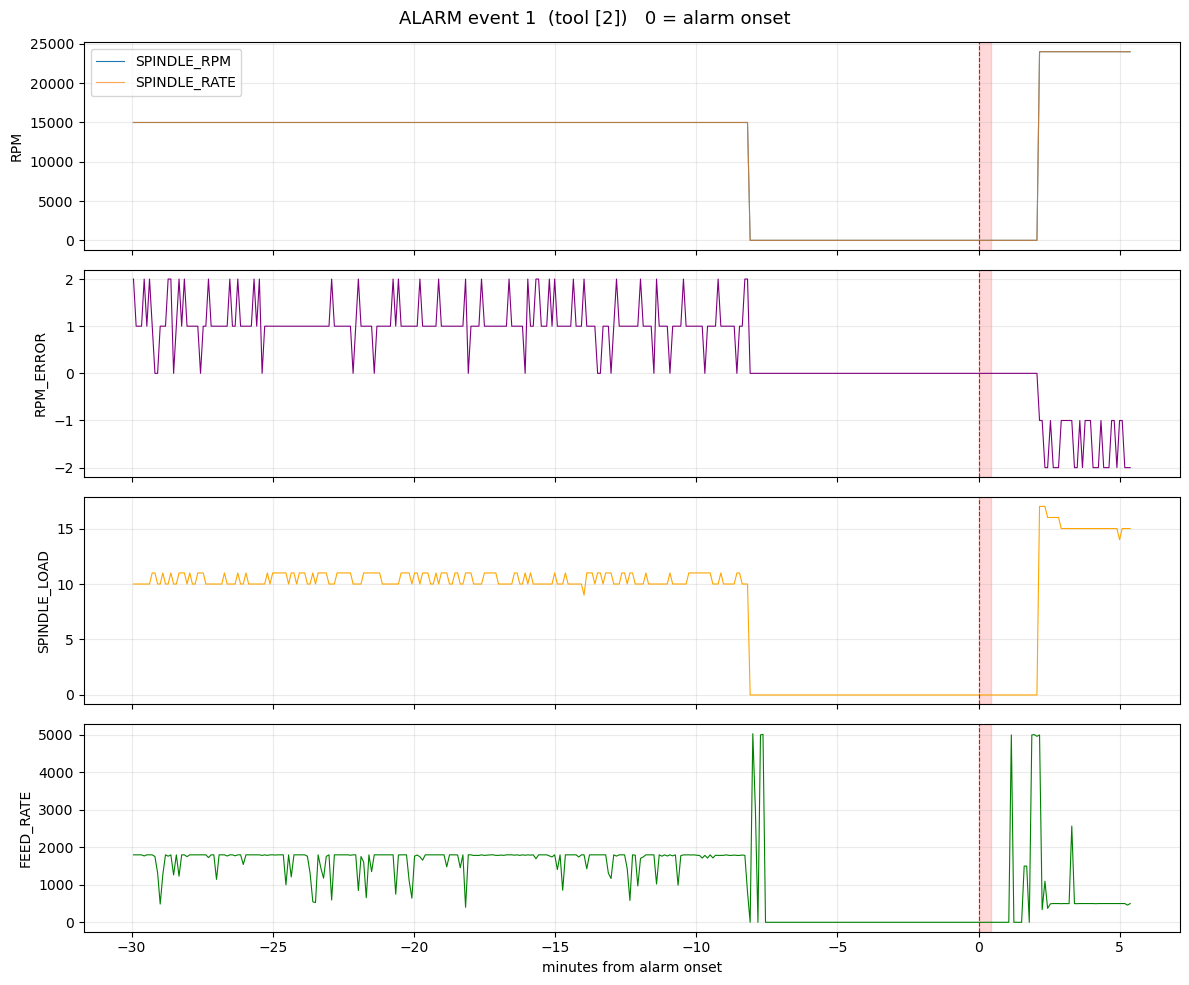

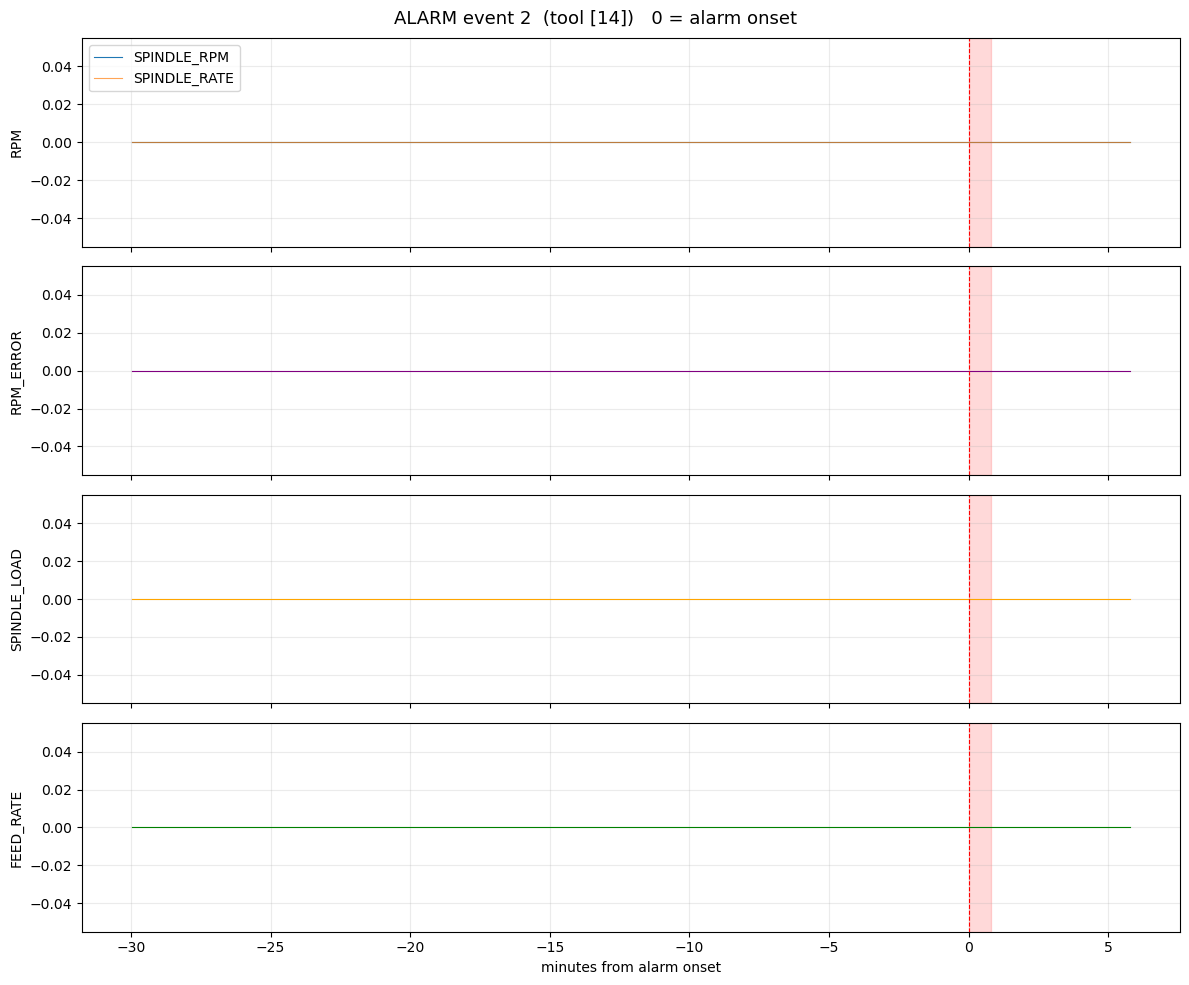


[안내] 위 표/그래프에서 30min_before → during 방향으로
LOAD 상승 / RPM_std 증가 / |RPM_ERROR| 증가 / FEED 급변이 보이는지 확인하세요.


In [8]:
# =============================================================
# [Cell 7] 실제 ALARM 2건 사전 징후 분석
# 대상: status == STATUS_ERROR (alarm=1) 연속 구간 2건
# 목적: ALARM 발생 전 LOAD 상승 / RPM 변동성 / RPM_ERROR / FEED 변화
#       같은 사전 징후가 실제로 있었는지 확인. 없으면 없다고 결론.
# 주의: 가상 이상 생성/모델 학습 없음. 사전 구간은 필터 없이 원본 흐름 사용.
# =============================================================
import matplotlib.pyplot as plt

# --- 0) 전체 데이터를 시간순으로 (RPM_ERROR 포함) ---
d = df.sort_values("timestamp").reset_index(drop=True).copy()
d["rpm_error"] = d["spindle_rate"] - d["spindle_rpm"]
d["is_cutting"] = (d["status"] == "STATUS_RUN") & (d["spindle_rpm"] > 0) & (d["feed_rate"] > 0)

# --- 1) ALARM 연속 이벤트 묶기 ---
err = d[d["status"] == "STATUS_ERROR"].copy()
# 앞 행과 120초 넘게 떨어지면 새 이벤트로 분리
gap = err["timestamp"].diff().dt.total_seconds()
err["event_id"] = (gap.isna() | (gap > 120)).cumsum()

events = (err.groupby("event_id")
             .agg(start=("timestamp", "min"),
                  end=("timestamp", "max"),
                  n_rows=("timestamp", "size"),
                  tools=("current_tool", lambda s: sorted(s.unique().tolist())))
             .reset_index())
print("=" * 70)
print(f"감지된 ALARM 연속 이벤트: {len(events)}건")
print("=" * 70)
print(events.to_string(index=False))

# --- 2) 구간 정의 (이벤트 시작 시각 기준 상대 구간) ---
# 각 구간: (라벨, 시작 오프셋초, 끝 오프셋초). 음수=발생 전.
SEGMENTS = [
    ("30min_before", -1800, -600),
    ("10min_before", -600,  -300),
    ("5min_before",  -300,  -60),
    ("1min_before",  -60,   -5),
    ("just_before",  -5,     0),
    ("during",       0,      None),   # 이벤트 지속 구간 (start~end)
]
VALUE_COLS = ["spindle_rpm", "spindle_rate", "rpm_error",
              "spindle_load", "feed_rate"]

def segment_stats(event_row):
    t0 = event_row["start"]
    t_end = event_row["end"]
    rows = []
    for label, a, b in SEGMENTS:
        if label == "during":
            seg = d[(d["timestamp"] >= t0) & (d["timestamp"] <= t_end)]
        else:
            lo = t0 + pd.Timedelta(seconds=a)
            hi = t0 + pd.Timedelta(seconds=b)
            seg = d[(d["timestamp"] >= lo) & (d["timestamp"] < hi)]

        rec = {"segment": label,
               "n": len(seg),
               "run_n": int(seg["is_cutting"].sum()),
               "tool": seg["current_tool"].mode().iat[0] if len(seg) else np.nan}
        for c in VALUE_COLS:
            if len(seg):
                rec[f"{c}_mean"] = round(seg[c].mean(), 2)
                rec[f"{c}_max"]  = round(seg[c].max(), 2)
                rec[f"{c}_std"]  = round(seg[c].std(), 2)
            else:
                rec[f"{c}_mean"] = rec[f"{c}_max"] = rec[f"{c}_std"] = np.nan
        rows.append(rec)
    return pd.DataFrame(rows)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 240)

seg_results = {}
for _, ev in events.iterrows():
    eid = ev["event_id"]
    print("\n" + "#" * 90)
    print(f"# ALARM 이벤트 {eid}: {ev['start']} ~ {ev['end']} "
          f"| 공구 {ev['tools']} | {ev['n_rows']}행")
    print("#" * 90)

    stats = segment_stats(ev)
    seg_results[eid] = stats

    # 보기 좋게 변수별로 mean/max/std 묶어 출력
    show_cols = ["segment", "n", "run_n", "tool"]
    print("\n[구간별 표본 수 / 절삭행 수 / 주요 공구]")
    print(stats[show_cols].to_string(index=False))
    for c in VALUE_COLS:
        cc = ["segment", f"{c}_mean", f"{c}_max", f"{c}_std"]
        print(f"\n[{c}]")
        print(stats[cc].to_string(index=False))

# --- 3) 시간 흐름 그래프 (이벤트별, 발생 30분 전 ~ 발생 직후 5분) ---
for _, ev in events.iterrows():
    eid = ev["event_id"]
    t0, t_end = ev["start"], ev["end"]
    lo = t0 - pd.Timedelta(minutes=30)
    hi = t_end + pd.Timedelta(minutes=5)
    w = d[(d["timestamp"] >= lo) & (d["timestamp"] <= hi)].copy()
    tsec = (w["timestamp"] - t0).dt.total_seconds() / 60.0  # 분 단위 (0=발생)

    fig, ax = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
    fig.suptitle(f"ALARM event {eid}  (tool {ev['tools']})   0 = alarm onset",
                 fontsize=13)

    ax[0].plot(tsec, w["spindle_rpm"], label="SPINDLE_RPM", lw=0.8)
    ax[0].plot(tsec, w["spindle_rate"], label="SPINDLE_RATE", lw=0.8, alpha=0.7)
    ax[0].set_ylabel("RPM"); ax[0].legend(loc="upper left")

    ax[1].plot(tsec, w["rpm_error"], color="purple", lw=0.8)
    ax[1].set_ylabel("RPM_ERROR")

    ax[2].plot(tsec, w["spindle_load"], color="orange", lw=0.8)
    ax[2].set_ylabel("SPINDLE_LOAD")

    ax[3].plot(tsec, w["feed_rate"], color="green", lw=0.8)
    ax[3].set_ylabel("FEED_RATE"); ax[3].set_xlabel("minutes from alarm onset")

    for a in ax:
        a.axvspan(0, (t_end - t0).total_seconds()/60.0, color="red", alpha=0.15)
        a.axvline(0, color="red", ls="--", lw=0.8)
        a.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

print("\n[안내] 위 표/그래프에서 30min_before → during 방향으로")
print("LOAD 상승 / RPM_std 증가 / |RPM_ERROR| 증가 / FEED 급변이 보이는지 확인하세요.")

In [9]:
# =============================================================
# [Cell 8] RPM>0 & FEED=0 (861행) 발생 맥락 분석
# 전제: 이 861행을 '이상'으로 가정하지 않는다. 실제 맥락만 확인.
# 목적: 정상 공정전환/드웰인지 / 고부하 특이상황인지 /
#       특정 공구 집중인지 / 가상이상 참고사례로 쓸 가치가 있는지 판단.
# 주의: 라벨링/가상이상 생성 없음.
# =============================================================

# --- 0) 전체 시간축 준비 (직전/직후 참조용) ---
d = df.sort_values("timestamp").reset_index(drop=True).copy()
d["rpm_error"] = d["spindle_rate"] - d["spindle_rpm"]
d["is_cutting"] = (d["status"] == "STATUS_RUN") & (d["spindle_rpm"] > 0) & (d["feed_rate"] > 0)

# --- 대상 정의: STATUS_RUN & RPM>0 & FEED=0 ---
mask = (d["status"] == "STATUS_RUN") & (d["spindle_rpm"] > 0) & (d["feed_rate"] == 0)
tgt = d[mask].copy()
print("대상 행 수 (RPM>0 & FEED=0):", len(tgt))

# --- 1) 날짜/시간 발생 분포 ---
print("\n[1] 날짜별 발생 개수")
print(tgt["timestamp"].dt.date.value_counts().sort_index().to_string())
print("\n[시간대(hour)별 발생 개수]")
print(tgt["timestamp"].dt.hour.value_counts().sort_index().to_string())

# --- 2) 공구별 발생 개수 ---
print("\n[2] CURRENT_TOOL별 발생 개수")
tool_cnt = tgt["current_tool"].value_counts()
print(tool_cnt.to_string())
# 각 공구의 '절삭 전체 대비' 비율도 참고 (특정 공구 집중 여부)
cut_tool = d[d["is_cutting"]].groupby("current_tool").size()
ratio = (tool_cnt / cut_tool * 100).round(3).dropna().sort_values(ascending=False)
print("\n[공구별: FEED=0 발생 / 해당공구 절삭행 수 비율(%)]")
print(ratio.to_string())

# --- 3) 연속 구간(이벤트) 묶기 ---
# 원본 인덱스가 연속이면 같은 이벤트. (시간순 정렬된 d 기준)
tgt_idx = tgt.index.to_series()
break_new = tgt_idx.diff().ne(1)          # 인덱스가 1씩 안 늘면 새 구간
tgt = tgt.assign(seg_id=break_new.cumsum())
n_events = tgt["seg_id"].nunique()
print(f"\n[3] 연속 구간(이벤트) 총 개수: {n_events}")

# --- 4) 구간별 지속시간/길이 ---
seg = (tgt.groupby("seg_id")
          .agg(start=("timestamp", "min"),
               end=("timestamp", "max"),
               n_rows=("timestamp", "size"),
               tool=("current_tool", lambda s: s.mode().iat[0]),
               rpm_mean=("spindle_rpm", "mean"),
               load_mean=("spindle_load", "mean"),
               load_max=("spindle_load", "max"),
               rpmerr_mean=("rpm_error", "mean"))
          .reset_index())
seg["duration_s"] = (seg["end"] - seg["start"]).dt.total_seconds()
seg = seg.round(2)

print("\n[4] 연속 구간 길이 분포 (행 수)")
print(seg["n_rows"].describe().round(2).to_string())
print("\n[연속 구간 지속시간(초) 분포]")
print(seg["duration_s"].describe().round(2).to_string())
print("\n[단일 행 구간 vs 다중 행 구간]")
print("  1행짜리 구간:", (seg["n_rows"] == 1).sum())
print("  2행 이상 구간:", (seg["n_rows"] >= 2).sum())
print("  최장 구간(행수):", seg["n_rows"].max(),
      "/ 최장 지속시간(초):", seg["duration_s"].max())

# 상위 길이 구간 몇 개 미리보기
print("\n[가장 긴 구간 상위 10개]")
print(seg.sort_values("n_rows", ascending=False)
         .head(10)[["seg_id","start","tool","n_rows","duration_s",
                    "rpm_mean","load_mean","load_max","rpmerr_mean"]]
         .to_string(index=False))

# --- 5) 값 분포 (SPINDLE_RPM / SPINDLE_LOAD / RPM_ERROR) ---
print("\n[5] 대상 861행의 값 분포")
for c in ["spindle_rpm", "spindle_load", "rpm_error"]:
    s = tgt[c]
    print(f"\n  [{c}]  mean={s.mean():.2f}  median={s.median():.1f} "
          f" p95={s.quantile(0.95):.1f}  max={s.max()}  min={s.min()}")
print("\n[SPINDLE_LOAD 구간별 개수]")
load_bins = pd.cut(tgt["spindle_load"],
                   bins=[-1,0,10,50,100,999],
                   labels=["0","1-10","11-50","51-100",">100"])
print(load_bins.value_counts().sort_index().to_string())

# --- 6) is_spindle_overload(60행)와 겹침 ---
print("\n[6] 과부하(is_spindle_overload=True)와의 겹침")
overload_all = int(d["is_spindle_overload"].sum())
overlap = int(tgt["is_spindle_overload"].sum())
print(f"  전체 과부하 행: {overload_all}")
print(f"  그 중 RPM>0&FEED=0 구간에 포함: {overlap} "
      f"({overlap/overload_all*100:.1f}% of overload)")
print(f"  861행 중 과부하 비율: {overlap/len(tgt)*100:.2f}%")

# --- 7) 구간 직전/직후 FEED_RATE 변화 ---
# 각 연속구간의 시작 직전 행, 끝 직후 행을 원본 d에서 참조
print("\n[7] 구간 직전/직후 FEED_RATE (전환 성격 확인)")
before_feed, after_feed = [], []
before_cut, after_cut = [], []
for sid, g in tgt.groupby("seg_id"):
    i0, i1 = g.index.min(), g.index.max()
    if i0 - 1 in d.index:
        before_feed.append(d.at[i0-1, "feed_rate"])
        before_cut.append(bool(d.at[i0-1, "is_cutting"]))
    if i1 + 1 in d.index:
        after_feed.append(d.at[i1+1, "feed_rate"])
        after_cut.append(bool(d.at[i1+1, "is_cutting"]))

before_feed, after_feed = pd.Series(before_feed), pd.Series(after_feed)
print(f"  직전 FEED>0 비율: {(before_feed>0).mean()*100:.1f}%  "
      f"(mean={before_feed.mean():.1f})")
print(f"  직후 FEED>0 비율: {(after_feed>0).mean()*100:.1f}%  "
      f"(mean={after_feed.mean():.1f})")
print(f"  직전이 절삭중이던 비율: {pd.Series(before_cut).mean()*100:.1f}%")
print(f"  직후가 절삭중이던 비율: {pd.Series(after_cut).mean()*100:.1f}%")
print("\n  해석 힌트: 직전·직후 모두 FEED>0(절삭) 이면 → 가공 중 '이송 순간정지(드웰/전환)'")
print("             직전 절삭 / 직후 정지(0) 이면 → 가공 종료 전환 성격")

대상 행 수 (RPM>0 & FEED=0): 861

[1] 날짜별 발생 개수
timestamp
2026-05-01      3
2026-05-04     11
2026-05-05     11
2026-05-06     14
2026-05-07    310
2026-05-08      9
2026-05-09     10
2026-05-10     33
2026-05-11     25
2026-05-12     48
2026-05-13     38
2026-05-14     14
2026-05-15      9
2026-05-16      8
2026-05-17     18
2026-05-18     48
2026-05-19     39
2026-05-20     19
2026-05-21     60
2026-05-22      8
2026-05-23     16
2026-05-24     10
2026-05-26     20
2026-05-27     33
2026-05-28     12
2026-05-29     20
2026-05-30     15

[시간대(hour)별 발생 개수]
timestamp
0      19
1      32
2      20
3      28
4       9
5      15
6      17
7      14
8       8
9       9
10      6
11     11
12     21
13     16
14     24
15     24
16    311
17     74
18     55
19     47
20     36
21     24
22     20
23     21

[2] CURRENT_TOOL별 발생 개수
current_tool
1     426
4     100
3      75
2      67
8      38
10     35
6      32
13     29
5      18
19     14
18      8
11      7
12      3
9       3
20      2
15

In [12]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt


# 전처리된 실제 기업 데이터
clean_df = pd.read_csv(
    "../output/mct_clean.csv",
    encoding="utf-8-sig",
    low_memory=False,
)


# EDA 그래프 저장 폴더
eda_report_dir = Path("../reports/eda")
eda_report_dir.mkdir(parents=True, exist_ok=True)


print("데이터 크기:", clean_df.shape)

print("\nSTATUS 분포:")
print(clean_df["status"].value_counts())

데이터 크기: (481648, 31)

STATUS 분포:
status
STATUS_RUN      243319
STATUS_READY    238313
STATUS_ERROR        16
Name: count, dtype: int64


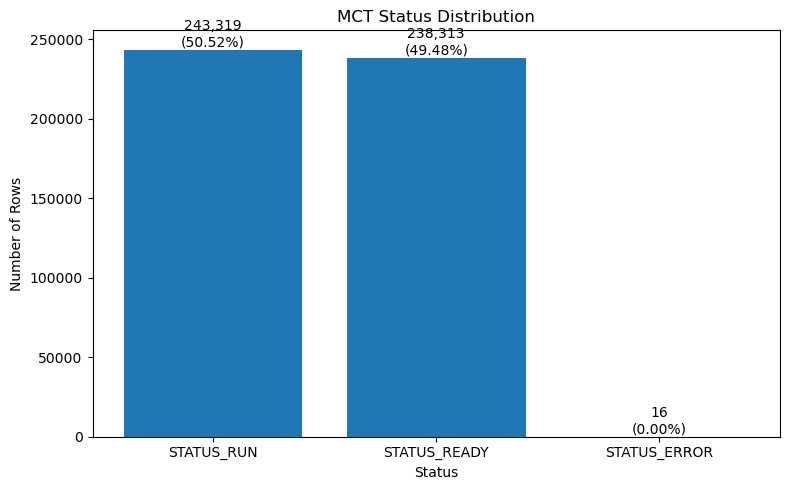

저장 완료: ..\reports\eda\status_distribution.png


In [13]:
# =========================================================
# STATUS 분포 그래프
# =========================================================

status_counts = clean_df["status"].value_counts()

status_order = [
    "STATUS_RUN",
    "STATUS_READY",
    "STATUS_ERROR",
]

status_counts = status_counts.reindex(status_order)

total = status_counts.sum()


fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    status_counts.index,
    status_counts.values,
)

ax.set_title("MCT Status Distribution")
ax.set_xlabel("Status")
ax.set_ylabel("Number of Rows")


# 막대 위에 개수 + 비율 표시
for bar, count in zip(bars, status_counts.values):

    percentage = count / total * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
    )


plt.tight_layout()

save_path = (
    eda_report_dir
    / "status_distribution.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("저장 완료:", save_path)

STATUS_RUN 전체: 243319
Cutting\n(RPM>0, FEED>0)      219195
Stopped\n(RPM=0, FEED=0)       16754
Feed Only\n(RPM=0, FEED>0)      6509
RPM Only\n(RPM>0, FEED=0)        861
dtype: int64

합계: 243319


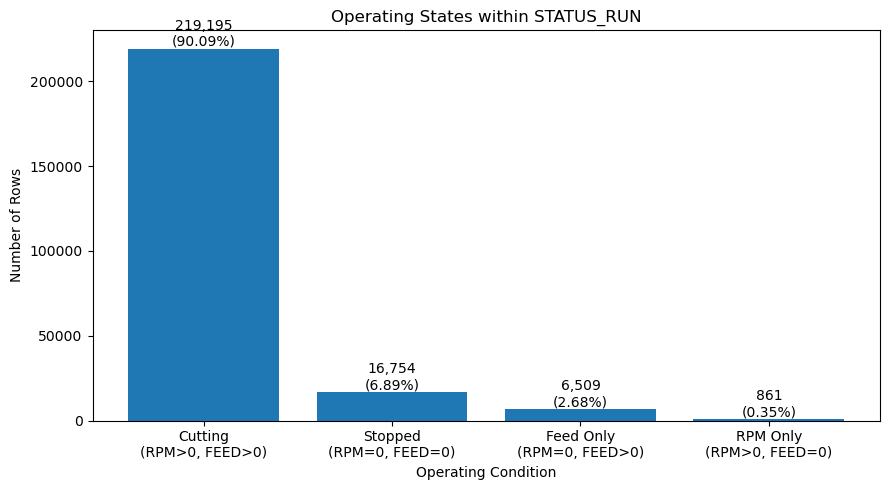

저장 완료: ..\reports\eda\run_cutting_distribution.png


In [14]:
# =========================================================
# STATUS_RUN 내부 운전 상태 분포
# =========================================================

run_df = clean_df[
    clean_df["status"] == "STATUS_RUN"
].copy()


cutting_counts = {
    "Cutting\n(RPM>0, FEED>0)": (
        (run_df["spindle_rpm"] > 0)
        & (run_df["feed_rate"] > 0)
    ).sum(),

    "Stopped\n(RPM=0, FEED=0)": (
        (run_df["spindle_rpm"] == 0)
        & (run_df["feed_rate"] == 0)
    ).sum(),

    "Feed Only\n(RPM=0, FEED>0)": (
        (run_df["spindle_rpm"] == 0)
        & (run_df["feed_rate"] > 0)
    ).sum(),

    "RPM Only\n(RPM>0, FEED=0)": (
        (run_df["spindle_rpm"] > 0)
        & (run_df["feed_rate"] == 0)
    ).sum(),
}


cutting_counts = pd.Series(cutting_counts)

print("STATUS_RUN 전체:", len(run_df))
print(cutting_counts)
print("\n합계:", cutting_counts.sum())


# 그래프
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    cutting_counts.index,
    cutting_counts.values,
)

ax.set_title("Operating States within STATUS_RUN")
ax.set_xlabel("Operating Condition")
ax.set_ylabel("Number of Rows")


# 막대 위 숫자와 비율
for bar, count in zip(
    bars,
    cutting_counts.values,
):
    percentage = count / len(run_df) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
    )


plt.tight_layout()

save_path = (
    eda_report_dir
    / "run_cutting_distribution.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("저장 완료:", save_path)

    current_tool   median  count
0              1   8990.0  33209
1              2   6990.0   4108
2              3  14989.0  23994
3              4  14989.0  66169
4              5  15990.0   6655
5              6  16991.0  19741
6              7  17989.0     98
7              8  17989.0   8109
8              9  19989.0    220
9             10  19989.0  15395
10            11  21491.0   1481
11            12  25990.0   1952
12            13  22001.0  17002
13            14  22001.0   3637
14            15  22001.0   3961
15            16  22001.0   7177
16            18  17989.0   3804
17            19  19989.0   2481
18            20   4009.0      2


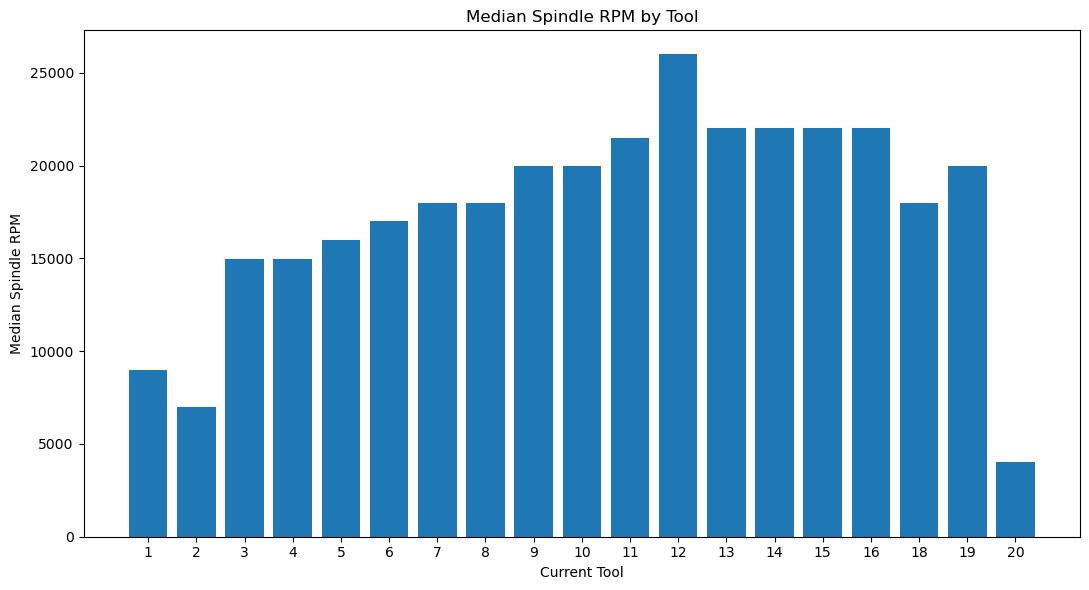

저장 완료: ..\reports\eda\tool_median_rpm.png


In [15]:
# =========================================================
# 공구별 절삭 RPM 중앙값
# =========================================================

cutting_df = clean_df[
    (clean_df["status"] == "STATUS_RUN")
    & (clean_df["spindle_rpm"] > 0)
    & (clean_df["feed_rate"] > 0)
].copy()


tool_rpm = (
    cutting_df
    .groupby("current_tool")["spindle_rpm"]
    .agg(["median", "count"])
    .reset_index()
    .sort_values("current_tool")
)


print(tool_rpm)


# 그래프
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    tool_rpm["current_tool"].astype(str),
    tool_rpm["median"],
)

ax.set_title("Median Spindle RPM by Tool")
ax.set_xlabel("Current Tool")
ax.set_ylabel("Median Spindle RPM")


plt.tight_layout()

save_path = (
    eda_report_dir
    / "tool_median_rpm.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("저장 완료:", save_path)

    current_tool  median  count
0              1     8.0  33209
1              2     6.0   4108
2              3    11.0  23994
3              4    11.0  66169
4              5    11.0   6655
5              6    12.0  19741
6              7    13.0     98
7              8    12.0   8109
8              9    13.0    220
9             10    13.0  15395
10            11    14.0   1481
11            12    17.0   1952
12            13    14.0  17002
13            14    14.0   3637
14            15    15.0   3961
15            16    15.0   7177
16            18    12.0   3804
17            19    14.0   2481
18            20     4.0      2


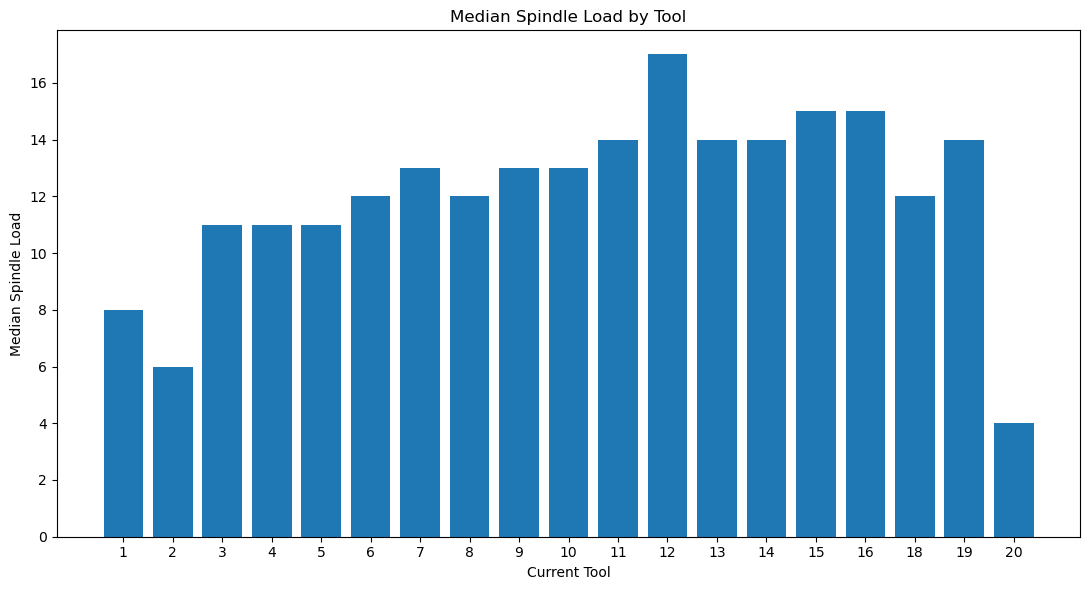

저장 완료: ..\reports\eda\tool_median_spindle_load.png


In [16]:
# =========================================================
# 공구별 절삭 SPINDLE_LOAD 중앙값
# =========================================================

tool_load = (
    cutting_df
    .groupby("current_tool")["spindle_load"]
    .agg(["median", "count"])
    .reset_index()
    .sort_values("current_tool")
)


print(tool_load)


# 그래프
fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    tool_load["current_tool"].astype(str),
    tool_load["median"],
)

ax.set_title("Median Spindle Load by Tool")
ax.set_xlabel("Current Tool")
ax.set_ylabel("Median Spindle Load")

plt.tight_layout()

save_path = (
    eda_report_dir
    / "tool_median_spindle_load.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("저장 완료:", save_path)

|RPM_ERROR| <= 5 비율: 98.37%

RPM_ERROR 통계:
count    219195.000000
mean          1.054372
std          41.139449
min         -31.000000
25%           0.000000
50%           1.000000
75%           2.000000
max        5339.000000
Name: rpm_error, dtype: float64


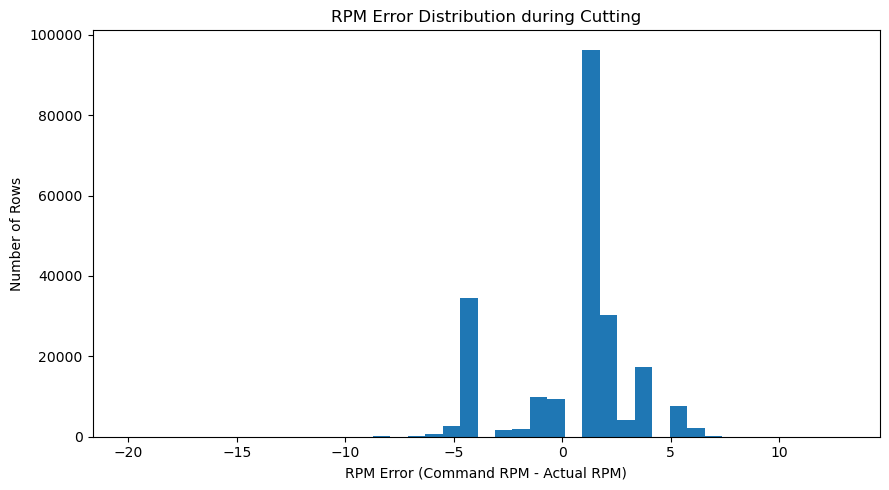

저장 완료: ..\reports\eda\rpm_error_distribution.png


In [18]:
# =========================================================
# RPM_ERROR 분포 - 중심 구간 확대
# =========================================================

cutting_df["rpm_error"] = (
    cutting_df["spindle_rate"]
    - cutting_df["spindle_rpm"]
)

within_5 = (
    cutting_df["rpm_error"].abs() <= 5
).mean() * 100

print(f"|RPM_ERROR| <= 5 비율: {within_5:.2f}%")

print("\nRPM_ERROR 통계:")
print(cutting_df["rpm_error"].describe())


# 그래프에서 볼 구간만 별도로 선택
rpm_error_plot = cutting_df[
    cutting_df["rpm_error"].between(-20, 20)
]["rpm_error"]


fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    rpm_error_plot,
    bins=41,
)

ax.set_title("RPM Error Distribution during Cutting")
ax.set_xlabel("RPM Error (Command RPM - Actual RPM)")
ax.set_ylabel("Number of Rows")

plt.tight_layout()

save_path = (
    eda_report_dir
    / "rpm_error_distribution.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("저장 완료:", save_path)

Sampling Interval 통계:
count    481647.000000
mean          5.560905
std           0.759161
min           4.181000
25%           5.371000
50%           5.419000
75%           5.750000
max         208.228000
Name: interval_seconds, dtype: float64


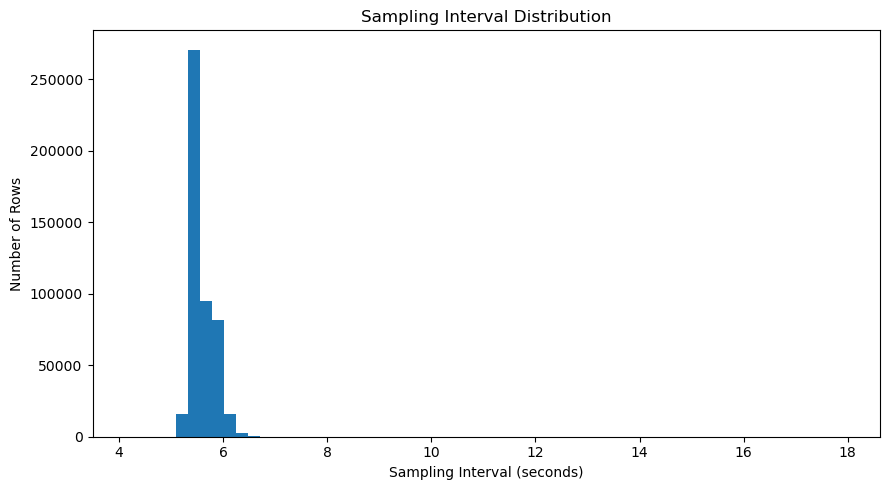

저장 완료: ..\reports\eda\sampling_interval_distribution.png


In [19]:
# =========================================================
# Sampling Interval 분포
# =========================================================

interval_df = clean_df[
    clean_df["interval_seconds"].notna()
].copy()


print("Sampling Interval 통계:")
print(interval_df["interval_seconds"].describe())


# 너무 큰 이상치는 그래프에서만 제외
interval_plot = interval_df[
    interval_df["interval_seconds"].between(0, 20)
]["interval_seconds"]


fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    interval_plot,
    bins=60,
)

ax.set_title("Sampling Interval Distribution")
ax.set_xlabel("Sampling Interval (seconds)")
ax.set_ylabel("Number of Rows")

plt.tight_layout()

save_path = (
    eda_report_dir
    / "sampling_interval_distribution.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("저장 완료:", save_path)